In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import patches
import seaborn as sns

In [2]:
df = pd.read_csv('./abalone/abalone.data',header=None,names=['sex','length','diameter','height','whole_weight','shucked_weight','viscera_weight','shell_weight','rings'])
df['sex'] = df.pop('sex')
# df = df[df['sex'] != 'I']
print(df.shape)
df.head()

(4177, 9)


,length,diameter,height,whole_weight,shucked_weight,viscera_weight,shell_weight,rings,sex
0,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15,M
1,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7,M
2,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9,F
3,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10,M
4,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7,I


In [3]:
print('NaN values of each columns:')
print(df.isna().sum())

NaN values of each columns:
length            0
diameter          0
height            0
whole_weight      0
shucked_weight    0
viscera_weight    0
shell_weight      0
rings             0
sex               0
dtype: int64


In [4]:
print('Count of duplicated rows:')
print(df.duplicated().sum())

Count of duplicated rows:
0


In [5]:
print('Datatypes of each columns:')
print(df.dtypes)

Datatypes of each columns:
length            float64
diameter          float64
height            float64
whole_weight      float64
shucked_weight    float64
viscera_weight    float64
shell_weight      float64
rings               int64
sex                object
dtype: object


# **Preprocessing**

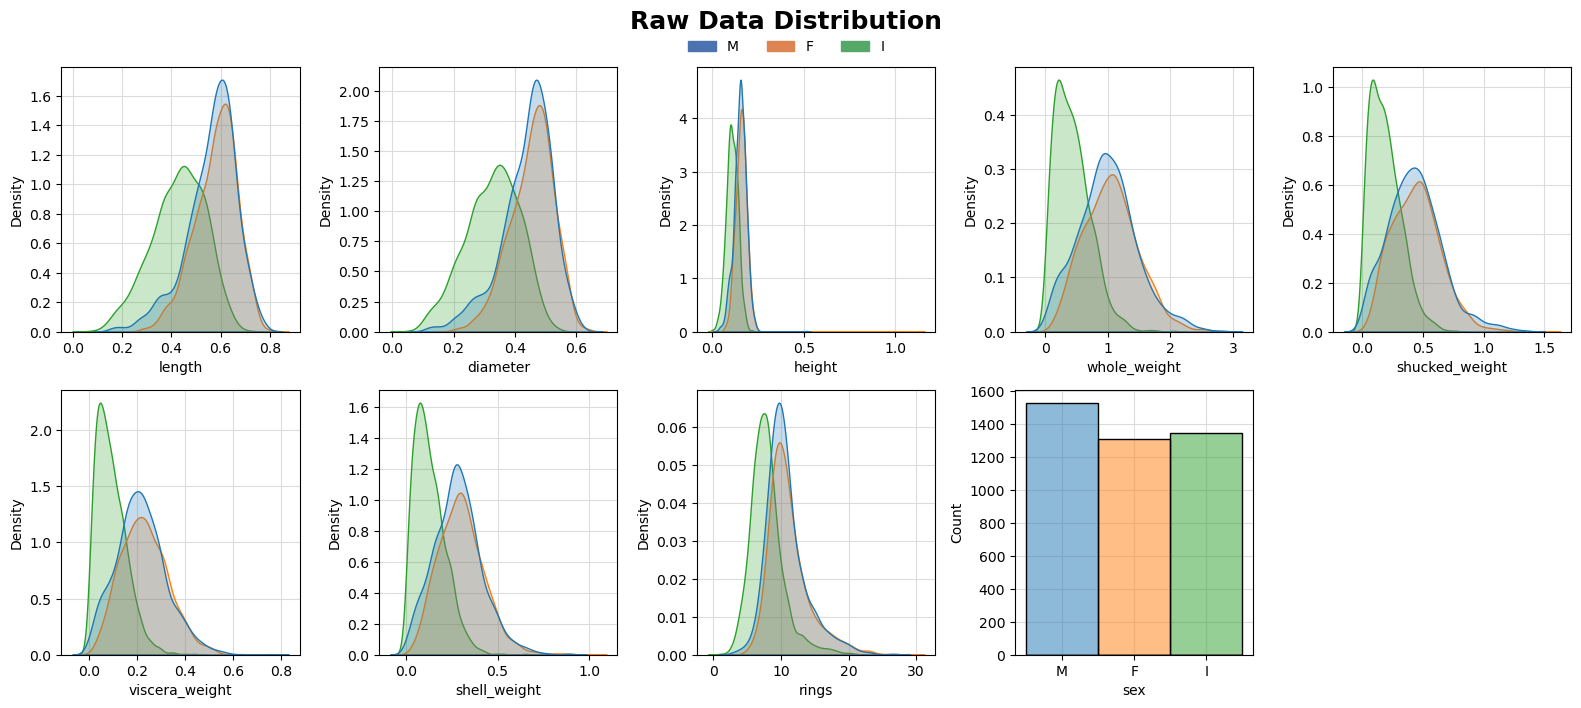

In [19]:
fig = plt.figure(figsize=(16,7))
for i,col in enumerate(df.columns):
    plt.subplot(2,5,i+1)
    plt.grid(color='gainsboro',zorder=1)
    if i != 8:
        sns.kdeplot(df,x=col,zorder=2,hue='sex',legend=False,hue_order=['M','F','I'],fill=True)
    else:
        sns.histplot(df,x=col,zorder=2,hue='sex',legend=False,hue_order=['M','F','I'])
handles = [
    patches.Patch(label='M',color=sns.color_palette('deep')[0]),
    patches.Patch(label='F',color=sns.color_palette('deep')[1]),
    patches.Patch(label='I',color=sns.color_palette('deep')[2])
]
fig.legend(handles=handles,loc='upper center',ncols=3,frameon=False,bbox_to_anchor=(0.5,0.98))
plt.suptitle('Raw Data Distribution',size=18,weight='bold',y=1.005)
plt.tight_layout()
plt.show()

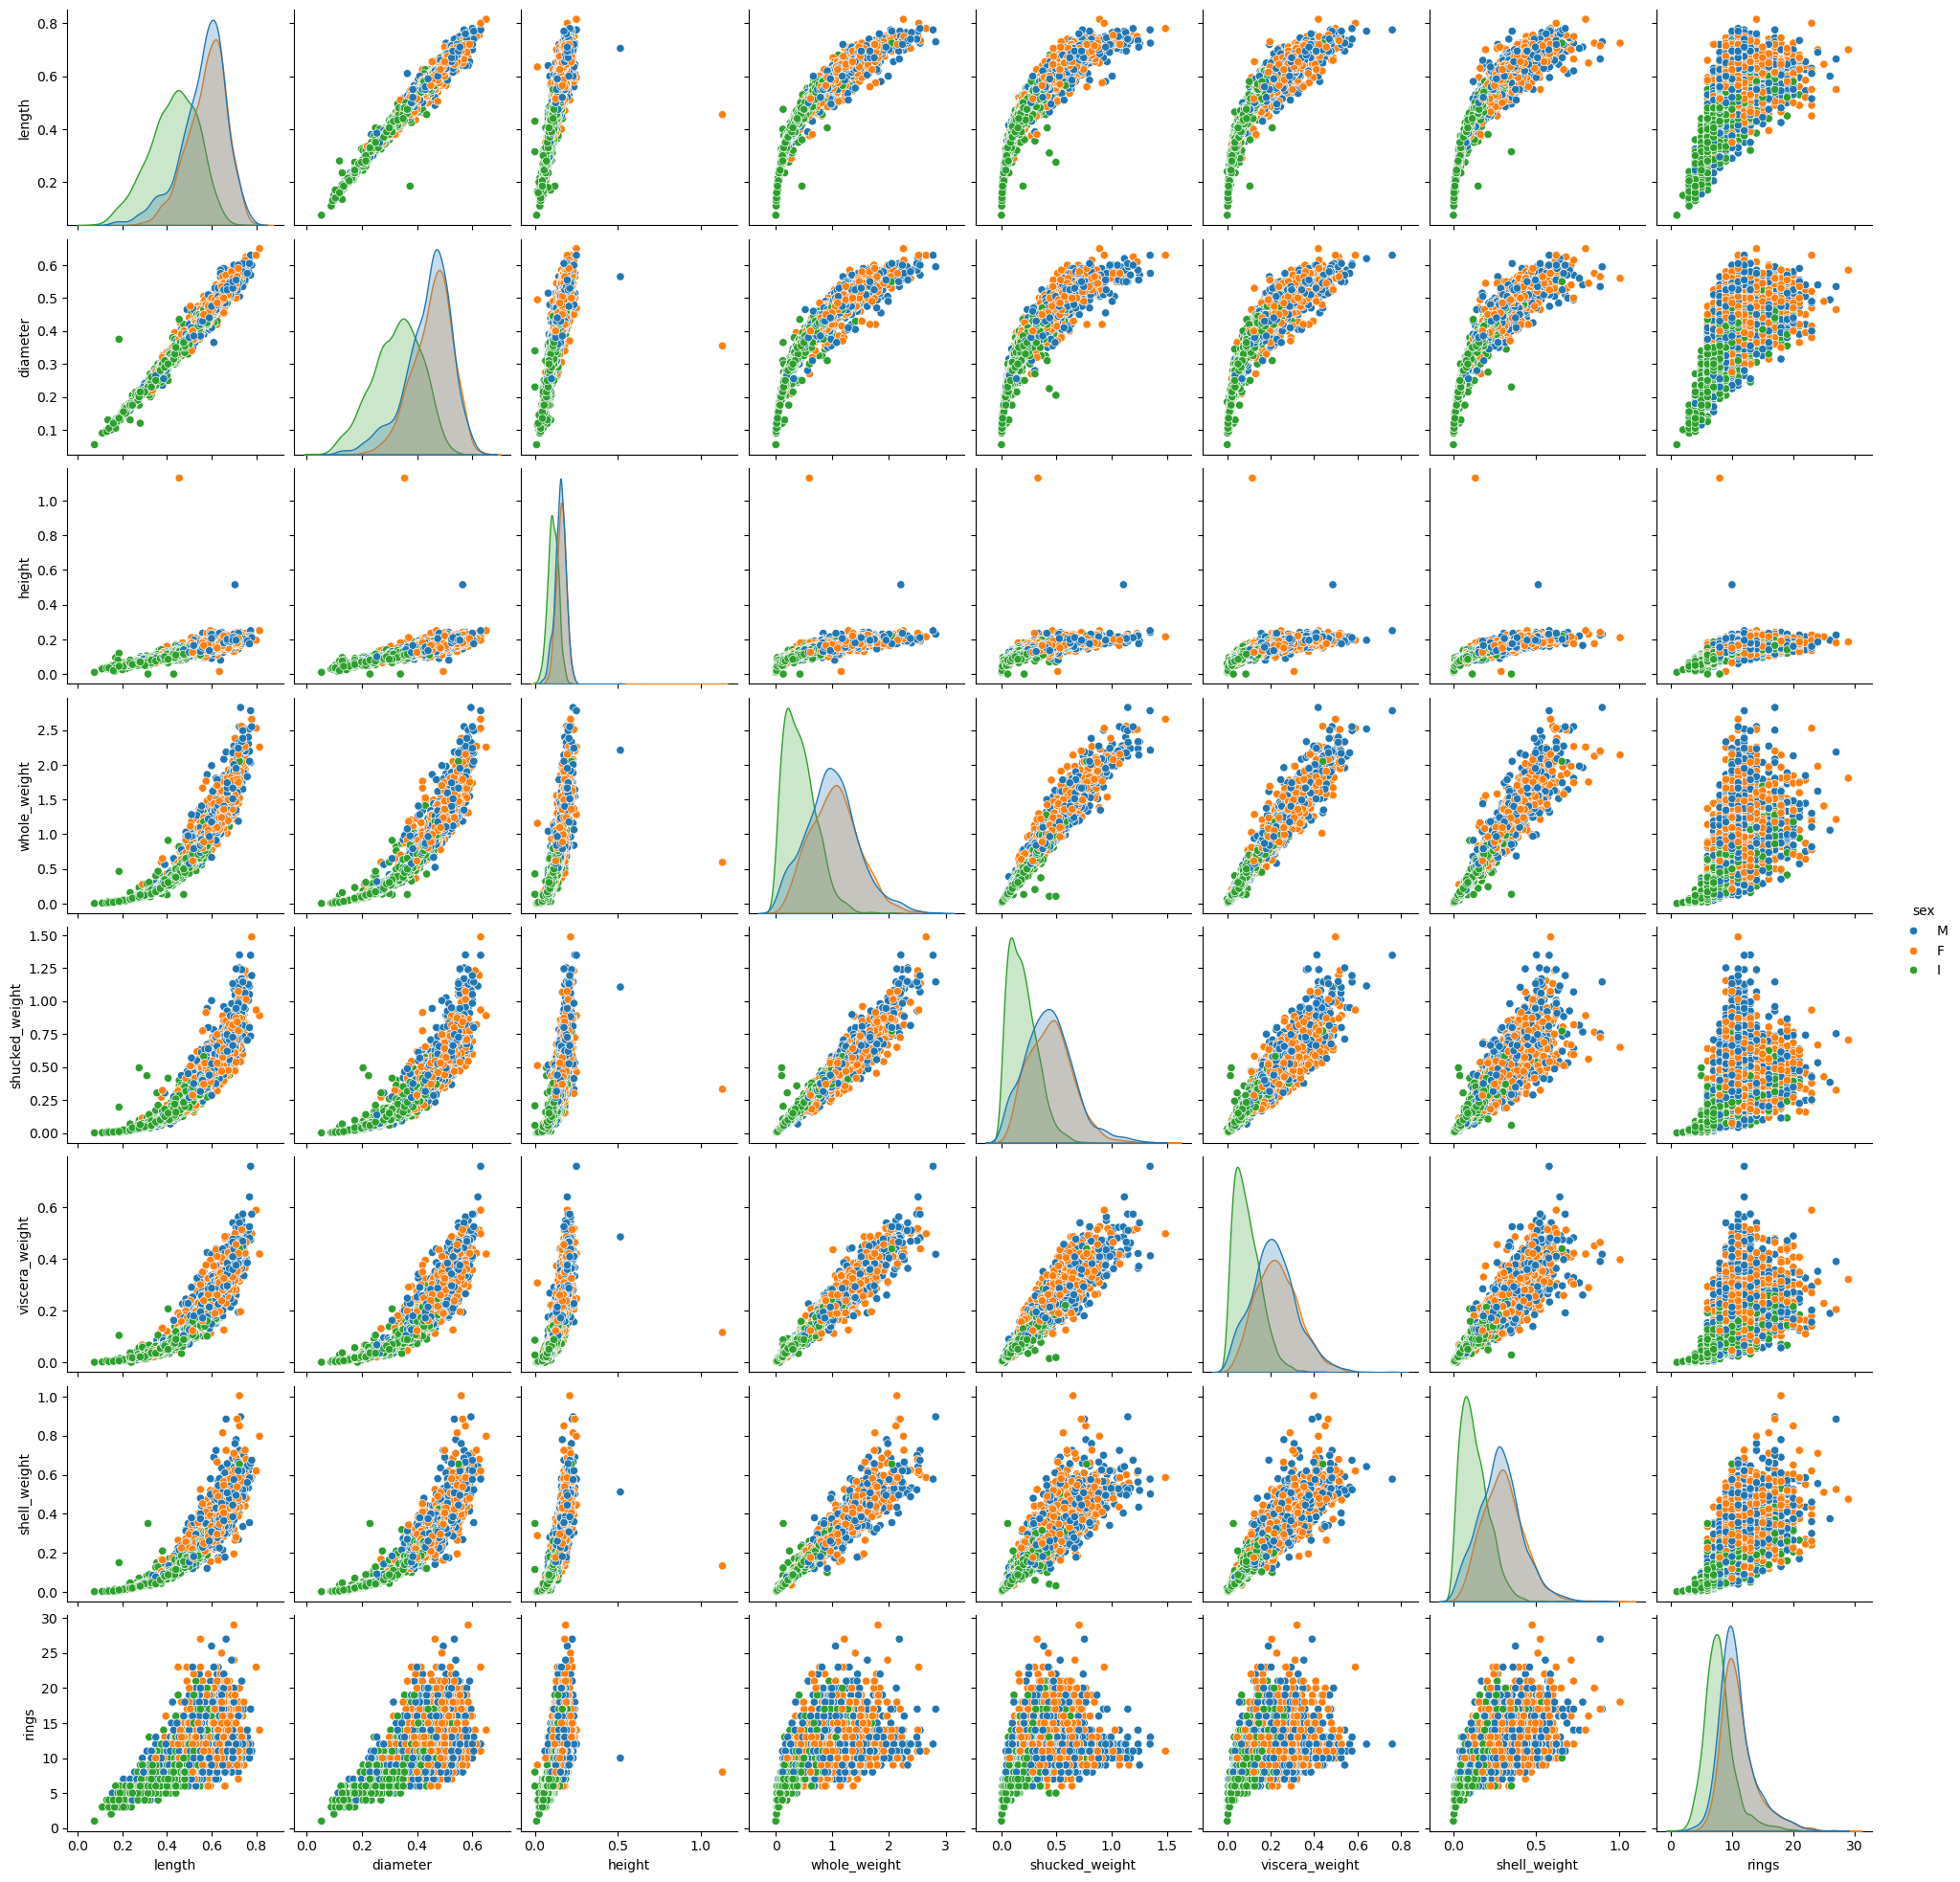

In [20]:
sns.pairplot(df,hue='sex',hue_order=['M','F','I'])
plt.show()

In [21]:
from sklearn.model_selection import train_test_split

X = df.drop('sex',axis=1)
y = df['sex'].to_numpy()

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [22]:
from modules.autolog import ASLT

aslt = ASLT(beta=[-5,-5,30,5,5,5,5,5])
X_train_lt = aslt.fit_transform(X_train)
X_test_lt = aslt.transform(X_test)

df_train_lt = pd.DataFrame(X_train_lt,columns=X_train.columns)
df_train_lt['sex'] = y_train
print(f'Train shape: {df_train_lt.shape}')

df_test_lt = pd.DataFrame(X_test_lt,columns=X_test.columns)
df_test_lt['sex'] = y_test
print(f'Test shape: {df_test_lt.shape}')

df_train_lt = pd.DataFrame(X_train,columns=X_train.columns)
df_train_lt['sex'] = y_train
df_test_lt = pd.DataFrame(X_test,columns=X_test.columns)
df_test_lt['sex'] = y_test

Train shape: (3341, 9)
Test shape: (836, 9)


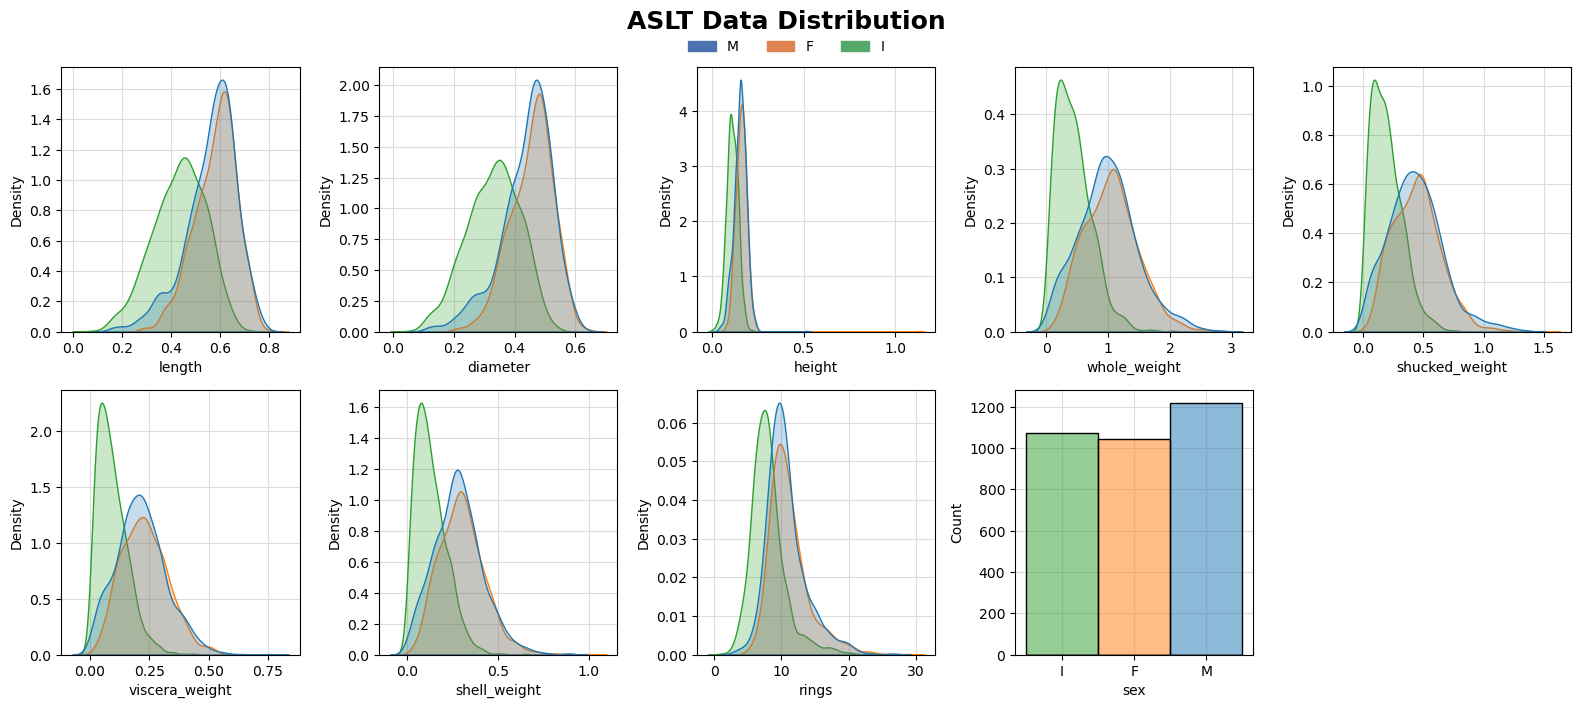

In [29]:
fig = plt.figure(figsize=(16,7))
for i,col in enumerate(df.columns):
    plt.subplot(2,5,i+1)
    plt.grid(color='gainsboro',zorder=1)
    if i != 8:
        sns.kdeplot(df_train_lt,x=col,zorder=2,hue='sex',legend=False,hue_order=['M','F','I'],fill=True)
    else:
        sns.histplot(df_train_lt,x=col,zorder=2,hue='sex',legend=False,hue_order=['M','F','I'])
fig.legend(handles=handles,loc='upper center',ncols=3,frameon=False,bbox_to_anchor=(0.5,0.98))
plt.suptitle('ASLT Data Distribution',size=18,weight='bold',y=1.005)
plt.tight_layout()
plt.show()

In [30]:
iqr_threshold = 3
df_train_or = df_train_lt.copy()
df_test_or = df_test_lt.copy()
for i,col in enumerate(df.columns):
    if col != 'sex':
        median = df_train_or[col].quantile(0.50)
        iqr = df_train_or[col].quantile(0.75)-df_train_or[col].quantile(0.25)
        condition = (median-iqr_threshold*iqr < df_train_or[col]) & (df_train_or[col] < median+iqr_threshold*iqr)
        df_train_or = df_train_or[condition].reset_index(drop=True)
df_train_or

,length,diameter,height,whole_weight,shucked_weight,viscera_weight,shell_weight,rings,sex
0,0.550,0.445,0.125,0.6720,0.2880,0.1365,0.210,11,I
1,0.475,0.355,0.100,0.5035,0.2535,0.0910,0.140,8,I
2,0.305,0.225,0.070,0.1485,0.0585,0.0335,0.045,7,F
3,0.275,0.200,0.065,0.1165,0.0565,0.0130,0.035,7,I
4,0.495,0.380,0.135,0.6295,0.2630,0.1425,0.215,12,M
...,...,...,...,...,...,...,...,...,...
3226,0.490,0.400,0.115,0.5690,0.2560,0.1325,0.145,9,F
3227,0.670,0.550,0.190,1.3905,0.5425,0.3035,0.400,12,F
3228,0.510,0.395,0.125,0.5805,0.2440,0.1335,0.188,11,M
3229,0.575,0.465,0.120,1.0535,0.5160,0.2185,0.235,9,M


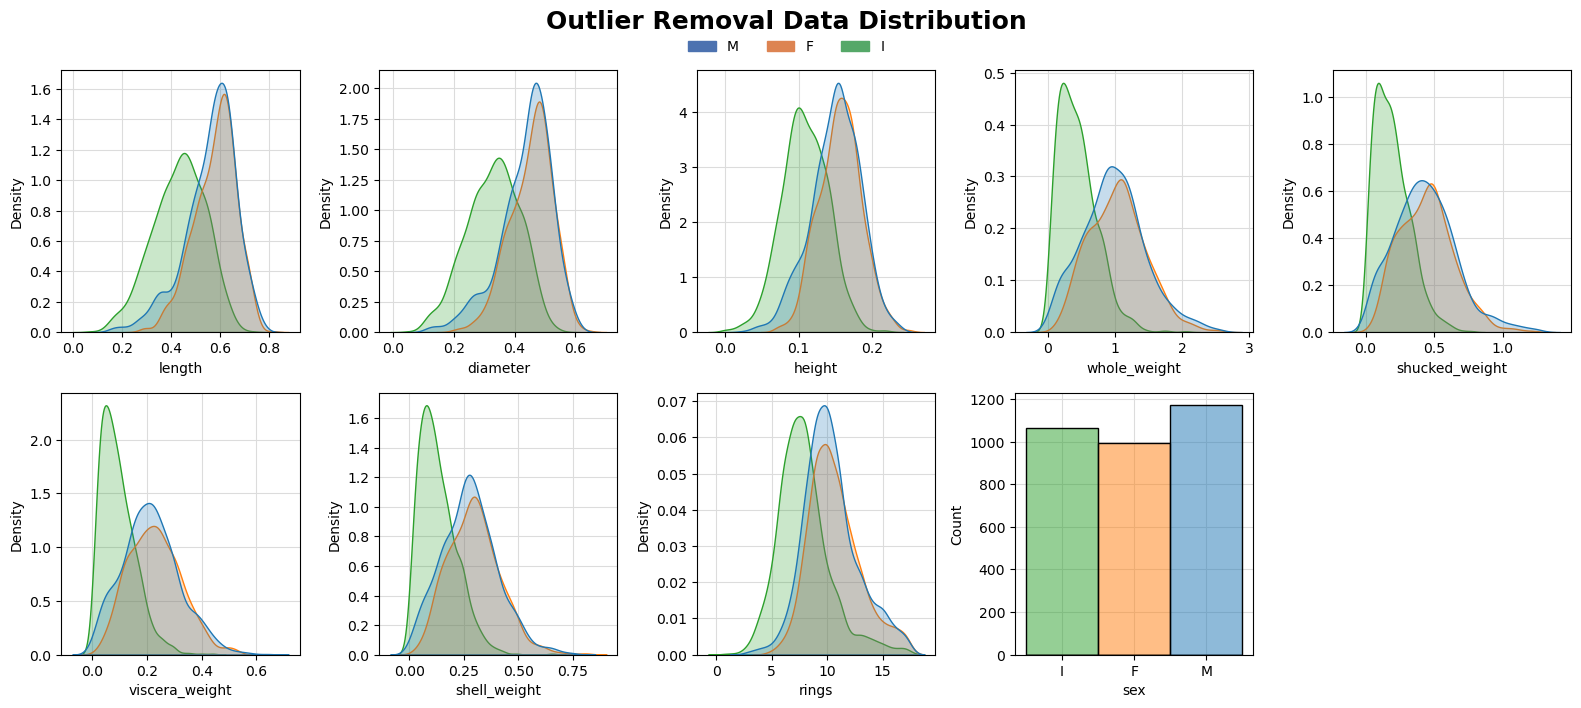

In [31]:
fig = plt.figure(figsize=(16,7))
for i,col in enumerate(df.columns):
    plt.subplot(2,5,i+1)
    plt.grid(color='gainsboro',zorder=1)
    if i != 8:
        sns.kdeplot(df_train_or,x=col,zorder=2,hue='sex',legend=False,hue_order=['M','F','I'],fill=True)
    else:
        sns.histplot(df_train_or,x=col,zorder=2,hue='sex',legend=False,hue_order=['M','F','I'])
fig.legend(handles=handles,loc='upper center',ncols=3,frameon=False,bbox_to_anchor=(0.5,0.98))
plt.suptitle('Outlier Removal Data Distribution',size=18,weight='bold',y=1.005)
plt.tight_layout()
plt.show()

In [32]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA,KernelPCA

preprocess_pl = Pipeline([
    ('scaler',StandardScaler()),
    ('pca',KernelPCA(kernel='linear',n_components=8))
])
ct = ColumnTransformer([
    ('preprocess',preprocess_pl,list(df.columns[:-1])),
    ('encoder',OrdinalEncoder(categories=[['M','F','I']]),['sex'])
],remainder='passthrough')
Xy_train_pr = ct.fit_transform(df_train_or)
Xy_test_pr = ct.transform(df_test_or)

X_train_pr = Xy_train_pr[:,:-1]
y_train_pr = Xy_train_pr[:,-1]
X_test_pr = Xy_test_pr[:,:-1]
y_test_pr = Xy_test_pr[:,-1]

X_train_pr.shape,y_train_pr.shape,X_test_pr.shape,y_test_pr.shape

((3231, 8), (3231,), (836, 8), (836,))

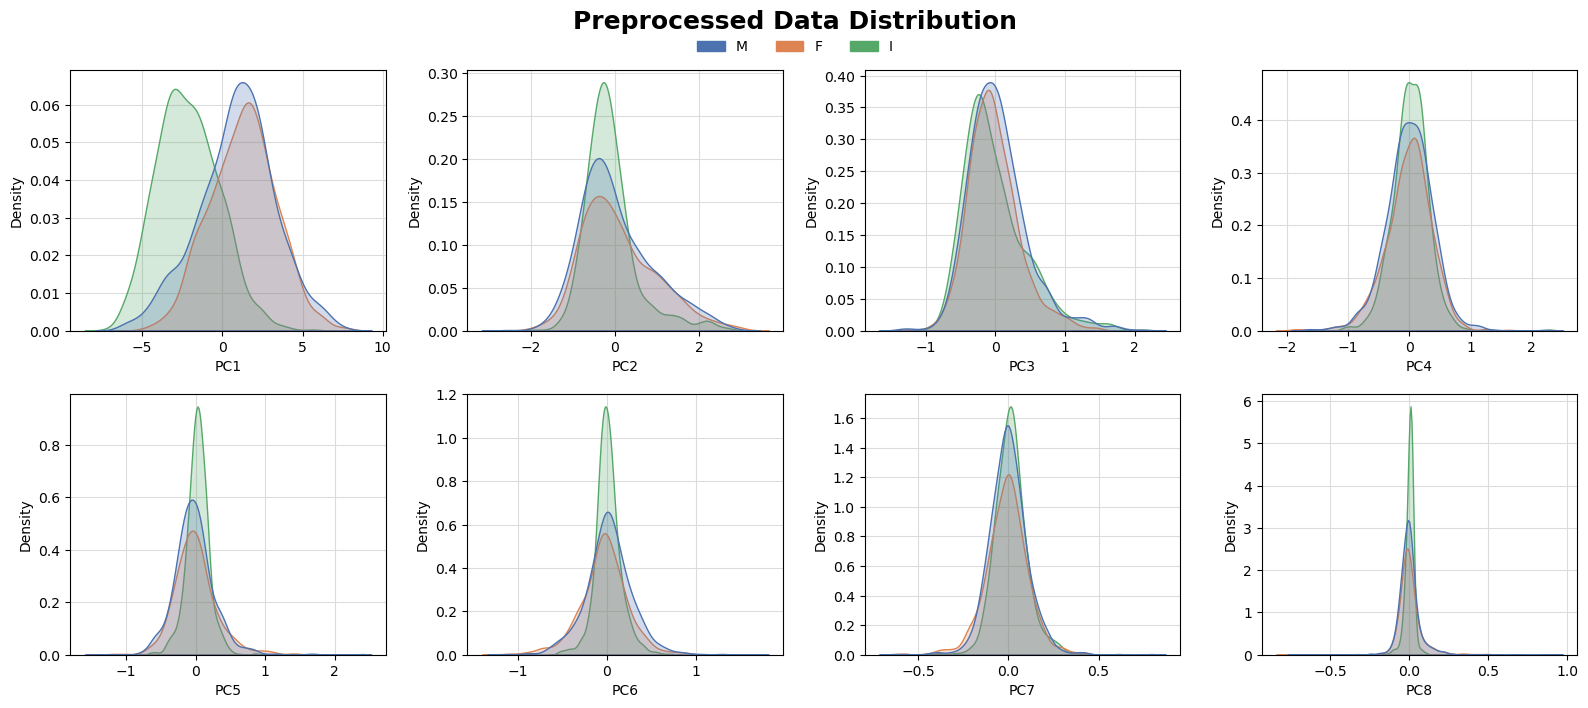

In [39]:
fig = plt.figure(figsize=(16,7))
for i in range(X_train_pr.shape[1]):
    plt.subplot(2,4,i+1)
    plt.grid(color='gainsboro',zorder=1)
    sns.kdeplot(x=X_train_pr[:,i],zorder=2,hue=y_train_pr,palette=[sns.color_palette('deep')[i] for i in range(3)],legend=False,hue_order=[0,1,2],fill=True)
    plt.xlabel(f'PC{i+1}')
fig.legend(handles=handles,loc='upper center',ncols=3,frameon=False,bbox_to_anchor=(0.5,0.98))
plt.suptitle('Preprocessed Data Distribution',size=18,weight='bold',y=1.005)
plt.tight_layout()
plt.show()

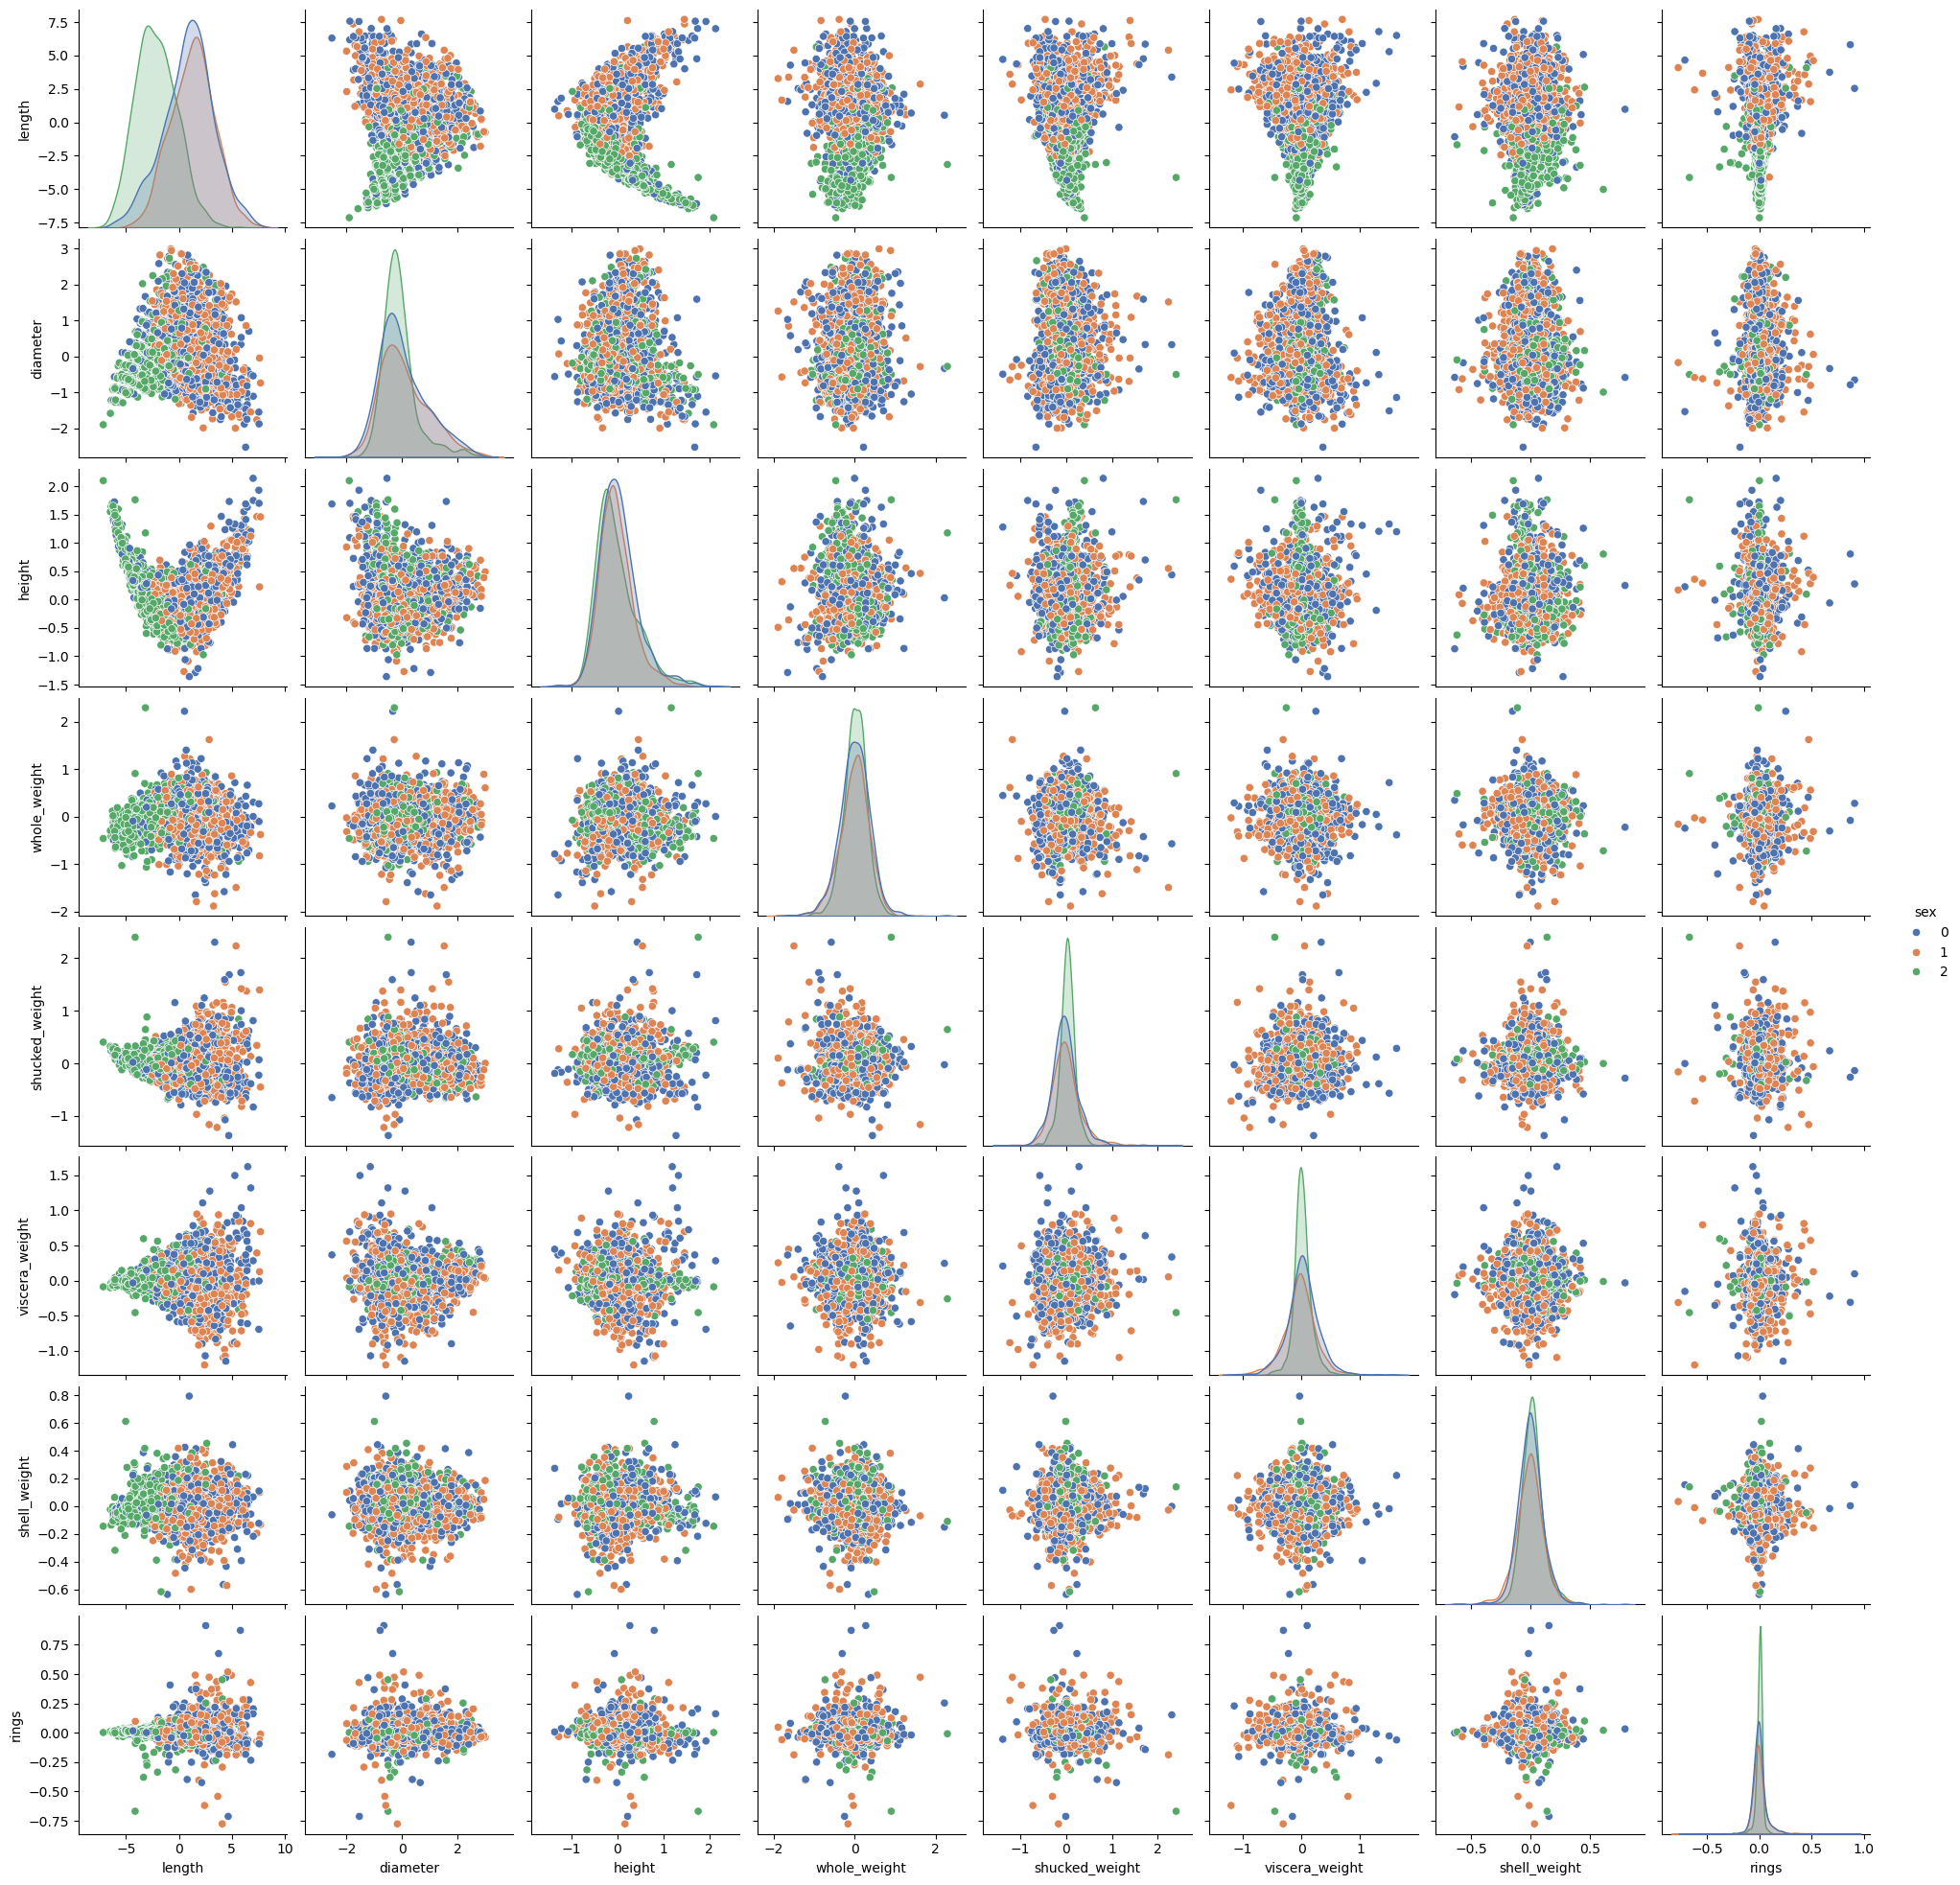

In [42]:
df_train_pr = pd.DataFrame(np.hstack([X_train_pr,y_train_pr.reshape(-1,1)]),columns=df_train_or.columns)

sns.pairplot(df_train_pr,hue='sex',hue_order=[0,1,2],palette=[sns.color_palette('deep')[i] for i in range(3)])
plt.show()

# **Modelling**

In [43]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
import optuna

def objective(trial):
    svc_C = trial.suggest_float('C',1e-2,1e1),
    svc_kernel = trial.suggest_categorical('kernel',['linear','poly','rbf'])

    svc = SVC(C=svc_C[0],kernel=svc_kernel,gamma='scale',degree=4)
    score = cross_val_score(svc,X_train_pr,y_train_pr,n_jobs=4,cv=4)
    accuracy = score.mean()
    return accuracy

svc_study = optuna.create_study(direction='maximize')
svc_study.optimize(objective,n_trials=100)

[I 2026-11-10 18:59:54,776] A new study created in memory with name: no-name-84b8c434-f21c-4e5e-b9e0-a52f83d1a848
[I 2026-11-10 18:59:57,348] Trial 0 finished with value: 0.46425268688578897 and parameters: {'C': 5.22676087735458, 'kernel': 'poly'}. Best is trial 0 with value: 0.46425268688578897.
[I 2026-11-10 18:59:57,575] Trial 1 finished with value: 0.5626775154281227 and parameters: {'C': 8.697146373316459, 'kernel': 'rbf'}. Best is trial 1 with value: 0.5626775154281227.
[I 2026-11-10 18:59:57,751] Trial 2 finished with value: 0.5586579220189678 and parameters: {'C': 2.112769081187742, 'kernel': 'rbf'}. Best is trial 1 with value: 0.5626775154281227.
[I 2026-11-10 18:59:58,432] Trial 3 finished with value: 0.471988218803293 and parameters: {'C': 8.055292966107139, 'kernel': 'poly'}. Best is trial 1 with value: 0.5626775154281227.
[I 2026-11-10 18:59:58,941] Trial 4 finished with value: 0.46610950593200584 and parameters: {'C': 6.063704962866367, 'kernel': 'poly'}. Best is trial 1

In [46]:
def objective(trial):
    rf_n_estimators = trial.suggest_int('n_estimators',10,500),
    rf_criterion = trial.suggest_categorical('criterion',['entropy','gini','log_loss'])

    rf = RandomForestClassifier(n_estimators=rf_n_estimators[0],criterion=rf_criterion)
    score = cross_val_score(rf,X_train_pr,y_train_pr,n_jobs=4,cv=4)
    accuracy = score.mean()
    return accuracy

rf_study = optuna.create_study(direction='maximize')
rf_study.optimize(objective,n_trials=100)

[I 2026-11-10 19:02:11,706] A new study created in memory with name: no-name-d3d68682-fa89-4547-ab03-c904dffa290f
[I 2026-11-10 19:02:14,573] Trial 0 finished with value: 0.5608157121474229 and parameters: {'n_estimators': 392, 'criterion': 'entropy'}. Best is trial 0 with value: 0.5608157121474229.
[I 2026-11-10 19:02:17,162] Trial 1 finished with value: 0.5571032242629468 and parameters: {'n_estimators': 496, 'criterion': 'log_loss'}. Best is trial 0 with value: 0.5608157121474229.
[I 2026-11-10 19:02:19,144] Trial 2 finished with value: 0.5595796219956568 and parameters: {'n_estimators': 378, 'criterion': 'log_loss'}. Best is trial 0 with value: 0.5608157121474229.
[I 2026-11-10 19:02:21,630] Trial 3 finished with value: 0.5536951580845817 and parameters: {'n_estimators': 473, 'criterion': 'entropy'}. Best is trial 0 with value: 0.5608157121474229.
[I 2026-11-10 19:02:22,189] Trial 4 finished with value: 0.5580333590979916 and parameters: {'n_estimators': 107, 'criterion': 'entropy'

In [44]:
svc = SVC(**svc_study.best_params)
svc.fit(X_train_pr,y_train_pr)
y_svc = svc.predict(X_test_pr)

rf = RandomForestClassifier(**rf_study.best_params)
rf.fit(X_train_pr,y_train_pr)
y_rf = rf.predict(X_test_pr)

NameError: name 'rf_study' is not defined

NameError: name 'y_rf' is not defined

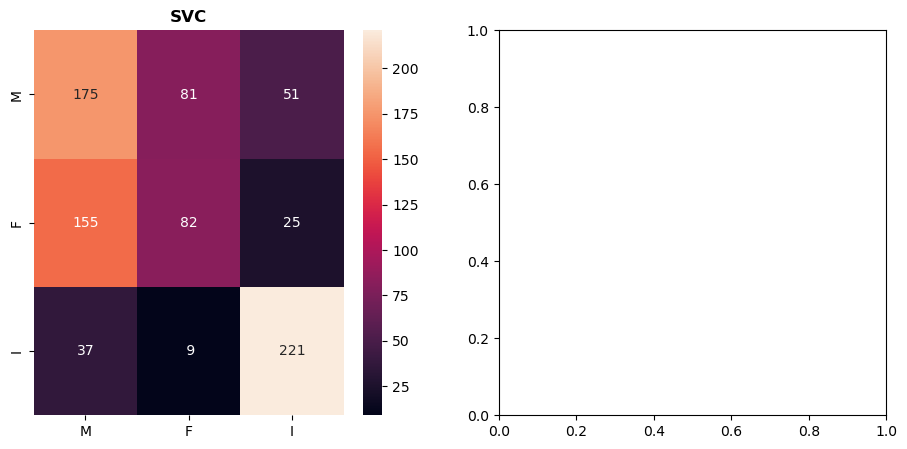

In [45]:
from sklearn.metrics import accuracy_score,recall_score,precision_score,f1_score,confusion_matrix

plt.figure(figsize=(11,5))
plt.subplot(1,2,1)
sns.heatmap(confusion_matrix(y_test_pr,y_svc),annot=True,fmt='2d',xticklabels=['M','F','I'],yticklabels=['M','F','I'])
plt.title('SVC',weight='bold')

plt.subplot(1,2,2)
sns.heatmap(confusion_matrix(y_test_pr,y_rf),annot=True,fmt='2d',xticklabels=['M','F','I'],yticklabels=['M','F','I'])
plt.title('RF',weight='bold')

plt.tight_layout()
plt.show()